In [19]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

# repo root, so src/ imports work
ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.data import load_merged_table, parse_dates, temporal_split

FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

# extracted folder if present, otherwise the archive
DATA = ROOT / "data" / "raw" / "full"
if not DATA.exists():
    DATA = ROOT / "data" / "raw" / "kenya_ppra_full.csv.tar.gz"

df = parse_dates(load_merged_table(DATA))
aw, train = temporal_split(df)
X_train, X_test = aw[train], aw[~train]

print("data:", DATA)
print("merged table (N x P):", df.shape)
print("scoring unit (awarded, in window):", aw.shape, "| excluded:", int(df["value_amount"].notna().sum()) - len(aw))
print(f"train: {len(X_train):,} ({train.mean():.1%}) | test: {len(X_test):,} ({1 - train.mean():.1%})")

data: /Users/razanosman/kenya-procurement-triage/data/raw/full
merged table (N x P): (277325, 23)
scoring unit (awarded, in window): (108984, 23) | excluded: 179
train: 72,585 (66.6%) | test: 36,399 (33.4%)


## Missingness

status                            99.88
tender_awardCriteria              73.39
contractPeriod_startDate          50.90
supplier_name                     33.76
contractPeriod_endDate            11.15
dateSigned                         6.35
tender_mainProcurementCategory     0.11
tender_tenderPeriod_startDate      0.04 



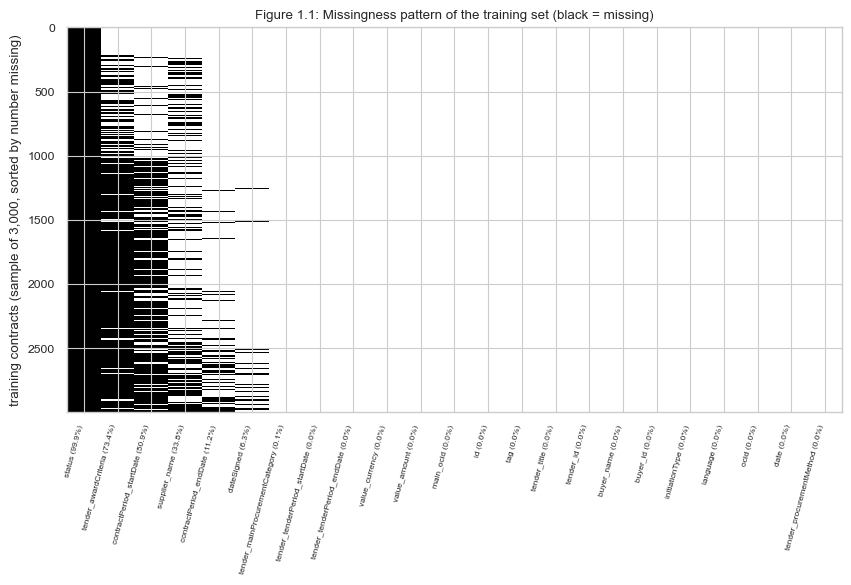

Little's MCAR test: chi2 = 2,526.8, df = 16, p = 0.00e+00, missingness patterns = 8



,missing %,chi2,dof,p,Cramer V,missing % by group,MCAR
column,,,,,,,
dateSigned,6.35,279.0,2,2.575732e-61,0.062,"{'open': 6.1, 'restricted': 13.78, 'non-competitive': 4.88}",rejected
contractPeriod_startDate,50.90,148.9,2,4.746722e-33,0.045,"{'open': 51.42, 'restricted': 39.71, 'non-competitive': 50.0}",rejected
contractPeriod_endDate,11.15,84.2,2,5.159527e-19,0.034,"{'open': 11.0, 'restricted': 9.47, 'non-competitive': 16.04}",rejected
supplier_name,33.76,42.2,2,6.762244e-10,0.024,"{'open': 33.47, 'restricted': 39.21, 'non-competitive': 35.09}",rejected
tender_mainProcurementCategory,0.06,44.3,2,2.433052e-10,0.027,"{'open': 0.05, 'restricted': 0.37, 'non-competitive': 0.0}",rejected
tender_awardCriteria,74.27,332.5,2,6.324472e-73,0.074,"{'open': 75.23, 'restricted': 67.0, 'non-competitive': 61.55}",rejected


In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
from src.constants import METHOD_LEVEL, LEVEL_NAMES
from src.diagnostics import little_mcar, missingness_tests

sns.set_theme(style="whitegrid", context="paper")


def save(fig, name):
    fig.savefig(FIG / name, dpi=300, bbox_inches="tight")
    plt.show()


# missing % per column, training set
miss_train = (X_train.isna().mean() * 100).round(2).sort_values(ascending=False)
print(miss_train[miss_train > 0].to_string(), "\n")

# Figure 1.1
order = miss_train.index
sample = X_train.sample(min(3000, len(X_train)), random_state=0)
sample = sample.loc[sample[order].isna().sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(10, 5))
ax.imshow(sample[order].isna().to_numpy(), aspect="auto", cmap="Greys", interpolation="nearest")
ax.set_xticks(range(len(order)))
ax.set_xticklabels([f"{c} ({miss_train[c]:.1f}%)" for c in order], rotation=75, ha="right", fontsize=6)
ax.set_ylabel("training contracts (sample of 3,000, sorted by number missing)")
ax.set_title("Figure 1.1: Missingness pattern of the training set (black = missing)")
save(fig, "fig1_1_missingness_heatmap.png")

# Little's MCAR test on the numeric block (days measured from the bidding deadline)
end = X_train["tender_tenderPeriod_endDate"]
block = pd.DataFrame({
    "log_value": np.log1p(X_train["value_amount"]),
    "days_to_signing": (X_train["dateSigned"] - end).dt.days,
    "contract_start_offset": (X_train["contractPeriod_startDate"] - end).dt.days,
    "contract_end_offset": (X_train["contractPeriod_endDate"] - end).dt.days,
})
chi2, dof, p, n_pat = little_mcar(block)
print(f"Little's MCAR test: chi2 = {chi2:,.1f}, df = {dof}, p = {p:.2e}, missingness patterns = {n_pat}\n")

# chi-square and Cramer's V against competition level
level = X_train["tender_procurementMethod"].map(METHOD_LEVEL)
award_cols = ["dateSigned", "contractPeriod_startDate", "contractPeriod_endDate", "supplier_name"]
tests_aw = missingness_tests(X_train, award_cols, level, LEVEL_NAMES)
tenders = X_train.drop_duplicates("ocid")
tests_t = missingness_tests(tenders, ["tender_mainProcurementCategory", "tender_awardCriteria"],
                            tenders["tender_procurementMethod"].map(METHOD_LEVEL), LEVEL_NAMES)
pd.concat([tests_aw, tests_t])

In [32]:
pd.set_option("display.max_colwidth", None)

# missing % by year across the whole scoring unit
year = aw["tender_tenderPeriod_endDate"].dt.year
cols = ["dateSigned", "contractPeriod_startDate", "contractPeriod_endDate", "supplier_name"]
print((aw[cols].isna().groupby(year).mean() * 100).round(1), "\n")

# same chi-square test, but against year instead of procurement method
missingness_tests(aw, cols, year)

                             dateSigned  contractPeriod_startDate  \
tender_tenderPeriod_endDate                                         
2018                               17.2                      21.5   
2019                                5.6                      12.5   
2020                                4.2                      23.7   
2021                                1.7                      82.8   
2022                                0.1                      87.1   
2023                               10.4                      38.7   
2024                               39.5                       2.2   
2025                                0.8                       2.0   
2026                                0.6                       1.4   

                             contractPeriod_endDate  supplier_name  
tender_tenderPeriod_endDate                                         
2018                                           24.2           13.2  
2019                             

,missing %,chi2,dof,p,Cramer V,missing % by group,MCAR
column,,,,,,,
dateSigned,13.66,21076.4,8,0.000000e+00,0.440,"{2018: 17.2, 2019: 5.56, 2020: 4.17, 2021: 1.72, 2022: 0.12, 2023: 10.44, 2024: 39.52, 2025: 0.77, 2026: 0.59}",rejected
contractPeriod_startDate,34.59,49490.0,8,0.000000e+00,0.674,"{2018: 21.52, 2019: 12.51, 2020: 23.73, 2021: 82.78, 2022: 87.07, 2023: 38.75, 2024: 2.16, 2025: 1.96, 2026: 1.41}",rejected
contractPeriod_endDate,10.45,1100.8,8,2.556862e-232,0.101,"{2018: 24.17, 2019: 8.83, 2020: 8.19, 2021: 11.6, 2022: 10.4, 2023: 10.55, 2024: 9.19, 2025: 9.1, 2026: 7.38}",rejected
supplier_name,26.83,15947.9,8,0.000000e+00,0.383,"{2018: 13.17, 2019: 63.47, 2020: 68.93, 2021: 36.76, 2022: 25.3, 2023: 26.88, 2024: 18.12, 2025: 0.47, 2026: 0.78}",rejected


In [33]:
tend = aw.drop_duplicates("ocid")
t_year = tend["tender_tenderPeriod_endDate"].dt.year
print((tend["tender_awardCriteria"].isna().groupby(t_year).mean() * 100).round(1), "\n")
missingness_tests(tend, ["tender_awardCriteria"], t_year)

tender_tenderPeriod_endDate
2018      0.3
2019      1.7
2020      8.7
2021     78.9
2022     99.5
2023     98.8
2024     98.5
2025    100.0
2026    100.0
Name: tender_awardCriteria, dtype: float64 



,missing %,chi2,dof,p,Cramer V,missing % by group,MCAR
column,,,,,,,
tender_awardCriteria,82.5,74587.2,8,0.0,0.903,"{2018: 0.31, 2019: 1.72, 2020: 8.7, 2021: 78.92, 2022: 99.54, 2023: 98.81, 2024: 98.48, 2025: 99.99, 2026: 99.96}",rejected


In [34]:
# earlier contracts per buyer at the moment of each contract (aw is sorted by date)
earlier = aw.groupby("buyer_id").cumcount()

counts = X_train.groupby("buyer_id").size()
print("buyers in training:", len(counts))
print("buyers with 100+ training contracts:", int((counts >= 100).sum()))
print(f"training contracts with 100+ earlier contracts from their buyer: {(earlier[train] >= 100).mean():.1%}")
print(f"test contracts with 100+ earlier contracts from their buyer: {(earlier[~train] >= 100).mean():.1%}")

buyers in training: 494
buyers with 100+ training contracts: 178
training contracts with 100+ earlier contracts from their buyer: 63.8%
test contracts with 100+ earlier contracts from their buyer: 85.7%


buyer groups (training): {'agency': 255, 'education': 117, 'county': 97, 'ministry': 25} 

indicator coverage (% of contracts)
                           train   test
f1_direct_award            100.0  100.0
f3_decision_period          93.7   71.8
f4_supplier_concentration   65.1   86.4
f5_benford_deviation        92.9   97.7
f5 under strict 100 rule    62.6   85.3 

signed before bidding closed: train 5.4%, test 9.0%
R(c) train: mean 0.278, median 0.277, skew 0.40
R(c) test:  mean 0.252, median 0.257


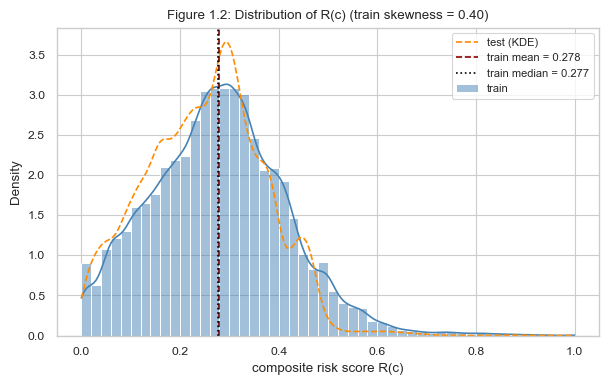

In [35]:
from scipy import stats
from src.features import IndicatorBuilder, INDICATORS, buyer_group

# fit on training contracts only, then score both sets
builder = IndicatorBuilder(k_prior=100, min_prior=10).fit(X_train)
F_train = builder.transform(X_train)
F_test = builder.transform(X_test)

print("buyer groups (training):", buyer_group(X_train.drop_duplicates("buyer_id")["buyer_name"]).value_counts().to_dict(), "\n")

# indicator coverage, with the Benford fallback shown against the strict 100 rule
cov = pd.DataFrame({
    "train": F_train[INDICATORS].notna().mean() * 100,
    "test": F_test[INDICATORS].notna().mean() * 100,
}).round(1)
cov.loc["f5 under strict 100 rule"] = [(F_train["n_prior_awards"] >= 100).mean() * 100,
                                       (F_test["n_prior_awards"] >= 100).mean() * 100]
print("indicator coverage (% of contracts)")
print(cov.round(1).to_string(), "\n")

print(f"signed before bidding closed: train {F_train['is_signed_pre_closure'].mean():.1%}, "
      f"test {F_test['is_signed_pre_closure'].mean():.1%}")
print(f"R(c) train: mean {F_train['R'].mean():.3f}, median {F_train['R'].median():.3f}, "
      f"skew {stats.skew(F_train['R'].dropna()):.2f}")
print(f"R(c) test:  mean {F_test['R'].mean():.3f}, median {F_test['R'].median():.3f}")

# Figure 1.2: target distribution
r = F_train["R"].dropna()
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(r, bins=50, kde=True, kde_kws={"clip": (0, 1)}, stat="density", ax=ax, color="steelblue", label="train")
sns.kdeplot(F_test["R"].dropna(), clip=(0, 1), ax=ax, color="darkorange", ls="--", label="test (KDE)")
ax.axvline(r.mean(), color="darkred", ls="--", label=f"train mean = {r.mean():.3f}")
ax.axvline(r.median(), color="black", ls=":", label=f"train median = {r.median():.3f}")
ax.set_xlabel("composite risk score R(c)")
ax.set_title(f"Figure 1.2: Distribution of R(c) (train skewness = {stats.skew(r):.2f})")
ax.legend(fontsize=8)
save(fig, "fig1_2_target_distribution.png")

In [36]:
from src.data import read_tables
from src.features import normalise_names

parties, sup = read_tables(DATA, ["parties", "awards_suppliers"])
ps = parties[parties["roles"].astype(str).str.contains("supplier")].copy()
ps["norm"] = normalise_names(ps["name"])
print(f"supplier party rows: {len(ps):,} | with identifier_id: {ps['identifier_id'].notna().mean():.1%}")
print("identifier schemes:", ps["identifier_scheme"].value_counts(dropna=False).head().to_dict(), "\n")

# is identifier_id one number per company?
known = ps.dropna(subset=["identifier_id"])
ids_per_name = known.groupby("norm")["identifier_id"].nunique()
names_per_id = known.groupby("identifier_id")["norm"].nunique()
print(f"names with a single identifier: {(ids_per_name == 1).mean():.1%} (of {len(ids_per_name):,} names)")
print(f"identifiers with a single name: {(names_per_id == 1).mean():.1%} (of {len(names_per_id):,} identifiers)\n")

print("examples of one identifier under several names:")
for i in names_per_id[names_per_id > 1].sort_values(ascending=False).index[:8]:
    print(" ", int(i), list(known.loc[known["identifier_id"] == i, "norm"].unique()[:4]))

# can the winning suppliers be linked to a party identifier? (same process, same name)
sup["norm"] = normalise_names(sup["name"])
lookup = ps[["main_ocid", "norm", "identifier_id"]].drop_duplicates(["main_ocid", "norm"])
linked = sup.merge(lookup, on=["main_ocid", "norm"], how="left")
print(f"\nwinning suppliers linked to an identifier: {linked['identifier_id'].notna().mean():.1%}")

supplier party rows: 552,087 | with identifier_id: 100.0%
identifier schemes: {'Bidders': 552087} 

names with a single identifier: 63.6% (of 174,028 names)
identifiers with a single name: 100.0% (of 552,087 identifiers)

examples of one identifier under several names:

winning suppliers linked to an identifier: 88.2%


In [37]:
import time
from src.entity_resolution import candidate_pairs, acronym_pairs, labelling_sample

# training supplier names only (the matcher is fit on train)
train_names = normalise_names(X_train["supplier_name"]).dropna()
volume = train_names.value_counts()
print(f"training awards with a supplier: {len(train_names):,} | distinct cleaned names: {len(volume):,}")
print(f"high-volume cut-off (top 5% of names): {volume.quantile(0.95):.0f}+ awards\n")

t0 = time.time()
fuzzy = candidate_pairs(volume.index, min_score=80)
acr = acronym_pairs(volume.index)
print(f"candidate pairs: {len(fuzzy):,} fuzzy (score 80+), {len(acr):,} acronym | {time.time() - t0:.0f}s")
print(f"same words in a different order (score 100, merged without labelling): {(fuzzy['score'] == 100).sum():,}\n")

sample, sizes = labelling_sample(pd.concat([fuzzy, acr], ignore_index=True), volume)
print("pairs in each stratum (population) and in the sample")
print(pd.DataFrame({"population": sizes, "sample": sample["stratum"].value_counts()}).to_string(), "\n")

labels_dir = ROOT / "data" / "labels"
labels_dir.mkdir(parents=True, exist_ok=True)
sample.to_csv(labels_dir / "entity_pairs_to_label.csv", index=False)
sizes.to_csv(labels_dir / "entity_pair_strata.csv")
print("saved", len(sample), "pairs to", labels_dir / "entity_pairs_to_label.csv")
sample.head(10)

training awards with a supplier: 48,079 | distinct cleaned names: 21,963
high-volume cut-off (top 5% of names): 6+ awards

candidate pairs: 199,827 fuzzy (score 80+), 29 acronym | 3s
same words in a different order (score 100, merged without labelling): 14

pairs in each stratum (population) and in the sample
                population  sample
stratum                           
80-85 | high         15574      22
80-85 | small       151024      22
85-90 | high          2880      22
85-90 | small        25121      22
90-95 | high           667      22
90-95 | small         3127      22
95-100 | high          337      22
95-100 | small        1083      22
acronym                 29      24 

saved 200 pairs to /Users/razanosman/kenya-procurement-triage/data/labels/entity_pairs_to_label.csv


,pair_id,stratum,score,name_a,name_b,awards_a,awards_b,label
0,1,80-85 | high,81,INOVATE ENTERPRISES LTD,FINETOPS ENTERPRISES LTD,7,1,
1,2,95-100 | small,95,MORKI VENTURES LTD,MORIKIN VENTURES LTD,2,1,
2,3,90-95 | high,90,STIMAL OFFICE SUPPLIES LTD,SAI OFFICE SUPPLIES LTD,6,2,
3,4,90-95 | high,93,MADISON GENERAL INSURANCE,MADISON GENERAL INSURANCE LTD,16,3,
4,5,acronym,24,MHE LTD,METUMI HEIGHTS ENTERPRISES,1,2,
5,6,acronym,19,KOI,K ONEGE INVESTMENT,1,2,
6,7,80-85 | high,82,PHARMACO HEALTHCARE LTD,PRODGY HEALTHCARE LTD,10,1,
7,8,95-100 | high,97,DELLAN HEIGHTS ENTERPRISES LTD,DELAN HEIGHTS ENTERPRISE LTD,18,1,
8,9,80-85 | high,82,RICANA ENTERPRISES LTD,SAWAGA ENTERPRISES LTD,26,1,
9,10,95-100 | high,98,OPTIMAL ENTREPRENEUR,OPTIMAL ENTREPRENEURS,9,1,


In [38]:
from src.entity_resolution import evaluate

labels_dir = ROOT / "data" / "labels"
labelled = pd.read_csv(labels_dir / "entity_pairs_labelled.csv", dtype={"label": str})
sizes = pd.read_csv(labels_dir / "entity_pair_strata.csv", index_col=0).iloc[:, 0]
print("labels:", labelled["label"].fillna("blank").value_counts().to_dict(), "\n")

# acronym rule on its own
acr = labelled[labelled["stratum"] == "acronym"]
dec = acr["label"].isin(["0", "1"])
print(f"acronym pairs: {len(acr)} | decided {dec.sum()} | same business {(acr['label'] == '1').sum()}"
      f" -> precision {(acr['label'] == '1').sum() / dec.sum():.2f}\n")

for name, use_acr in [("with acronym rule", True), ("without acronym rule", False)]:
    _, full, n = evaluate(labelled, sizes, use_acronym=use_acr)
    print(f"all suppliers, {name} ({n} labelled pairs, 95% bootstrap interval)")
    print(full.to_string(index=False), "\n")

# professor's split: high-volume vs small suppliers
for v in ["high", "small"]:
    _, full, n = evaluate(labelled[labelled["stratum"].str.endswith(v)], sizes, use_acronym=False)
    print(f"{v}-volume suppliers ({n} labelled pairs)")
    print(full.to_string(index=False), "\n")

labels: {'0': 115, '1': 69, 'blank': 16} 

acronym pairs: 24 | decided 17 | same business 6 -> precision 0.35

all suppliers, with acronym rule (184 labelled pairs, 95% bootstrap interval)
 threshold           metric  estimate   low  high
        85        precision     0.101 0.077 0.126
        85           recall     1.000 1.000 1.000
        85 false-match rate     0.152 0.149 0.155
        90        precision     0.540 0.418 0.667
        90           recall     0.844 0.720 0.959
        90 false-match rate     0.012 0.009 0.015
        95        precision     0.912 0.800 0.988
        95           recall     0.394 0.311 0.513
        95 false-match rate     0.001 0.000 0.001 

all suppliers, without acronym rule (184 labelled pairs, 95% bootstrap interval)
 threshold           metric  estimate   low  high
        85        precision     0.101 0.077 0.125
        85           recall     0.997 0.995 0.999
        85 false-match rate     0.152 0.148 0.155
        90        precision 

### Entity resolution option A: pre-specified test (written before fresh labelling)

- Option A = merge if cores are identical (after removing LTD, CO, AND, THE, M/S, T/A and plural S), or core score ≥ 95.
- Option B = merge if original token sort ratio ≥ 95 (selected on the first 184 labels).
- Both are evaluated only on a fresh sample that excludes the first 200 pairs.
- Adopt A if its precision is ≥ 0.90 and its recall is higher than B's on the same fresh pairs. Otherwise keep B.
- Core thresholds 90 and "identical cores only" are reported as sensitivity checks, not used to choose.

In [39]:
import importlib, src.entity_resolution
importlib.reload(src.entity_resolution)
from src.entity_resolution import core_pairs, fresh_sample

t0 = time.time()
cpairs = core_pairs(volume.index, min_score=85)
print(f"option A candidate pairs: {len(cpairs):,} | {time.time() - t0:.0f}s")
print(f"names merged by identical cores alone: {(cpairs['core_score'] == 100).sum():,} pairs\n")

old = pd.read_csv(labels_dir / "entity_pairs_labelled.csv")
fresh, fresh_sizes = fresh_sample(cpairs, volume, exclude=old, per_stratum=15)
print(pd.DataFrame({"population": fresh_sizes, "sample": fresh["stratum"].value_counts()}).to_string(), "\n")

fresh.to_csv(labels_dir / "entity_pairs_fresh_to_label.csv", index=False)
fresh_sizes.to_csv(labels_dir / "entity_pair_fresh_strata.csv")
print("saved", len(fresh), "pairs")
fresh.head(10)

option A candidate pairs: 26,057 | 3s
names merged by identical cores alone: 2,671 pairs

            population  sample
stratum                       
85-90            19256      15
90-95             2979      15
95-100            1084      15
exact core        2634      15 

saved 60 pairs


,pair_id,stratum,core_score,orig_score,name_a,name_b,awards_a,awards_b,label
0,1,95-100,95,80,AUTOEXPRESS,AUTOXPRESS LTD,3,26,
1,2,95-100,96,98,VILLA SURGICAL AND EQUIPMENTS,VILLA SURGICAL S AND EQUIPMENT,2,1,
2,3,85-90,88,80,VINNIM ENTERPRISES,VIONNE ENTERPRISES LTD,1,2,
3,4,exact core,100,80,BRITAM INSURANCE,BRITAM INSURANCES CO LTD,9,1,
4,5,exact core,100,90,NAIROBI IRONMONGERS,NAIROBI IRONMONGERS LTD,2,8,
5,6,95-100,95,87,BEMWATECH ENTERPRISES,BREWATECH ENTERPRISES LTD,1,1,
6,7,95-100,98,98,MOTORSZILLA ENTEPRISES,MOTORSZILLA ENTERPRISES,1,8,
7,8,95-100,97,88,ZAKALE EXPEDITIONS LTD,ZAKALE EXPENDITIONS,23,12,
8,9,95-100,98,99,TRIPLE A AGENCIES GENERAL SUPPLIERS,TRIPLE A AGENCIES GENERAL SUPPLIES,1,1,
9,10,90-95,91,82,KEVCY ENTERPRISES,KEVICK ENTERPRISES LTD,2,2,


In [40]:
# pairs option B would merge (original score 95+) that option A never lists as candidates
in_a = set(zip(cpairs["name_a"], cpairs["name_b"]))
b_pairs = fuzzy[fuzzy["score"] >= 95]
missed = b_pairs[[(min(a, b), max(a, b)) not in in_a
                  for a, b in zip(b_pairs["name_a"], b_pairs["name_b"])]]
print(f"option B merges: {len(b_pairs):,} | outside option A's candidates: {len(missed):,}")
missed.head(20)

option B merges: 1,434 | outside option A's candidates: 2


,name_a,name_b,score,kind
31282,ISAACWELLS LTD,ISAACWELLS LT5D,97,fuzzy
152240,CASCADE CO LD,CASCADE CO LTD,96,fuzzy


### Supplier resolver: cluster check (written before running on real data)

- The labelled samples validated pairs, not clusters. Linking pairs transitively (chaining) can join names that never matched directly.
- Inspect by hand: the 8 largest clusters, and every chained cluster whose lowest direct core score is below 90.
- If any contains different firms, the clustering step has a correctness problem and is fixed before f4 is used. Option A's pair rule (identical cores or core score ≥ 95) is not retuned.

In [ ]:
import importlib, src.entity_resolution, src.features
importlib.reload(src.entity_resolution); importlib.reload(src.features)
from src.features import IndicatorBuilder, normalise_names

t0 = time.time()
ib_res = IndicatorBuilder().fit(X_train)                          # option A resolver, training names only
ib_raw = IndicatorBuilder(resolve_suppliers=False).fit(X_train)   # stage-1 names, as before
res = ib_res.resolver_
print(f"fitted both builders in {time.time() - t0:.0f}s\n")

# 1. what the resolver did on training names
cl = res.clusters_
per_id = cl.groupby("id").agg(names=("name", "size"), awards=("awards", "sum"))
print(f"training supplier names: {len(cl):,} -> identities: {res.n_clusters_:,} "
      f"({len(cl) - res.n_clusters_:,} names merged into another)")
print("names per identity:", per_id["names"].value_counts().sort_index().to_dict(), "\n")

# 2. largest clusters, to check for chaining
print("largest clusters:")
for i in per_id.sort_values("names", ascending=False).head(8).index:
    members = cl.loc[cl["id"] == i, "name"].tolist()
    print(f"  [{len(members)}] {i}: {members[:12]}{' ...' if len(members) > 12 else ''}")

# chained clusters: some members only linked through others (lowest direct core score < 95)
from rapidfuzz import process, fuzz
from src.entity_resolution import core_name
low = {}
for i, g in cl[cl["cluster_size"] > 2].groupby("id"):
    cores = [" ".join(sorted(core_name(n).split())) for n in g["name"]]
    low[i] = process.cdist(cores, cores, scorer=fuzz.ratio).min()
low = pd.Series(low, dtype=float)
print(f"\nclusters with 3+ names: {len(low):,} | chained: {(low < 95).sum():,} | "
      f"chained with a direct score below 90: {(low < 90).sum():,}")
for i in low[low < 90].sort_values().head(5).index:
    print(f"  min direct score {low[i]:.0f}: {cl.loc[cl['id'] == i, 'name'].tolist()[:8]}")

# 3. how test-period names were resolved (training identities stay fixed)
tn = pd.Series(pd.unique(normalise_names(X_test["supplier_name"]).dropna()))
tid = res.transform(tn)
seen = tn.isin(set(res.name_map_))
new = tid.astype(str).str.startswith("~new:")
print(f"\ntest-period supplier names: {len(tn):,} | seen in training {seen.sum():,} | "
      f"linked to a training identity {(~seen & ~new).sum():,} | new identities {new.sum():,}\n")

# 4. effect on f4
for name, X in [("train", X_train), ("test", X_test)]:
    a = ib_res.transform(X)["f4_supplier_concentration"]
    b = ib_raw.transform(X)["f4_supplier_concentration"]
    both = a.notna() & b.notna()
    d = (a - b)[both]
    print(f"{name}: f4 coverage {a.notna().mean():.1%} (was {b.notna().mean():.1%}) | "
          f"changed by > 0.01: {(d.abs() > 0.01).mean():.1%} | mean change {d.mean():+.4f} | "
          f"Spearman with old f4 {a[both].corr(b[both], method='spearman'):.3f}")